# Online Shoppers Purchasing Intention: Predicting Buyers vs. Browsers

**Problem.** Most online retail traffic consists of light visitors who browse without completing a purchase. Retailers cannot easily differentiate genuine high-intent buyers from casual window shoppers, resulting in wasted ad spend and lost sales.

**Goal.** Build an end-to-end, leak-free machine learning classification system on the *Online Shoppers Purchasing Intention* dataset that predicts whether a web browsing session ends in a purchase (`Revenue`).


# **1. Importing Libraries**


In [1]:
import os, io, zipfile, warnings, glob, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_val_predict)
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier, StackingClassifier, VotingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve, roc_curve)
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
import joblib
import cloudpickle

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
import sklearn
import imblearn
import xgboost

print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("XGBoost:", xgboost.__version__)

Scikit-learn: 1.6.1
Imbalanced-learn: 0.14.2
XGBoost: 3.4.1


# **2. Load the Dataset**


In [3]:
CANDIDATE_NAMES = ["online_shoppers.csv", "online_shoppers", "online_shoppers_intention.csv", "online_shoppers_intention",]

def load_data():
    search_dirs = [Path("."), Path(".."), Path("/content"), Path("/mnt/user-data/uploads")]
    for base in search_dirs:
        for name in CANDIDATE_NAMES:
            p = base / name
            if p.is_file():
                print(f"Loading dataset from: {p.resolve()}")
                return pd.read_csv(p)

    for base in search_dirs:
        if base.exists():
            matched = list(base.glob("*online_shoppers*.csv"))
            if matched:
                print(f"Discovered matching CSV: {matched[0].resolve()}")
                return pd.read_csv(matched[0])

    try:
        from google.colab import files
        print("Dataset not found locally. Prompting Colab upload...")
        uploaded = files.upload()
        name = next(iter(uploaded))
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(uploaded[name])) as z:
                csv_inside = next(n for n in z.namelist() if n.lower().endswith(".csv"))
                with z.open(csv_inside) as f:
                    return pd.read_csv(f)
        return pd.read_csv(io.BytesIO(uploaded[name]))
    except (ImportError, ModuleNotFoundError):
        pass

    raise FileNotFoundError("Could not locate 'online_shoppers.csv' in the project directory.\n Please verify the dataset file is present in the workspace.")

df = load_data()
# Validate dataset structure
required_columns = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", "ProductRelated_Duration", "BounceRates",
                    "ExitRates", "PageValues", "SpecialDay", "Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend", "Revenue"]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

print("Dataset schema validated successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset not found locally. Prompting Colab upload...


Saving dataset.zip to dataset (1).zip
Dataset schema validated successfully.
Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# **3. Inspect the Data**


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [5]:
print("Missing values per column:")
missing_s = df.isnull().sum()
print(missing_s[missing_s > 0] if missing_s.sum() > 0 else "None")
print("\nDuplicate rows:", df.duplicated().sum())


Missing values per column:
None

Duplicate rows: 125


In [6]:
df.describe().T.round(3)


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000


In [7]:
print("Target distribution (raw):")
print(df["Revenue"].value_counts())
print((df["Revenue"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")


Target distribution (raw):
Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.53 %
True     15.47 %
Name: proportion, dtype: object


# **4. Cleaning Data**


In [8]:
# Remove duplicate observations
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. ", f"Remaining rows: {len(df)}")

# Convert binary columns safely
def to_binary(series, column_name):
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0, "yes": 1, "no": 0}
    mapped = series.astype(str).str.strip().str.lower().map(mapping)

    if mapped.isna().any():
        invalid = series[mapped.isna()].unique()

        raise ValueError(f"Unexpected values in {column_name}: {invalid}")
    return mapped.astype(int)


# Remove rows with missing target values
df = df.dropna(subset=["Revenue"]).reset_index(drop=True)

# Convert target and binary feature
df["Revenue"] = to_binary(df["Revenue"], "Revenue")
df["Weekend"] = to_binary(df["Weekend"], "Weekend")

# Report remaining missing values
print("\nMissing values after target cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nFinal class distribution:")
print(df["Revenue"].value_counts())

print("\nClass percentages:")
print((df["Revenue"].value_counts(normalize=True) * 100).round(2))

Removed 125 duplicate rows.  Remaining rows: 12205

Missing values after target cleaning:
Series([], dtype: int64)

Final class distribution:
Revenue
0    10297
1     1908
Name: count, dtype: int64

Class percentages:
Revenue
0    84.37
1    15.63
Name: proportion, dtype: float64


# **5. Train / Validation / Test Split (Strict Split Before EDA)**
To avoid **cognitive / human-snooping leakage**, we immediately partition our data before conducting exploratory data analysis. The test set simulates unobserved future production traffic and remains completely untouched until the final evaluation in Section 21.


In [9]:
# Separate features and target
X = df.drop(columns=["Revenue"])
y = df["Revenue"]

# First split: 80% development, 20% final test
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

# Second split: 60% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train_full)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nPurchase percentages:")
print("Training:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Training set: (7323, 17)
Validation set: (2441, 17)
Test set: (2441, 17)

Purchase percentages:
Training: 15.64 %
Validation: 15.61 %
Test: 15.65 %


In [10]:
X_threshold, y_threshold = X_val, y_val

# **6. Exploratory Data Analysis (Training Fold Only)**
Exploratory visualizations and correlation matrices are computed strictly on the training partition (`df_train`) to ensure zero leakage of validation or test statistics into our assumptions.


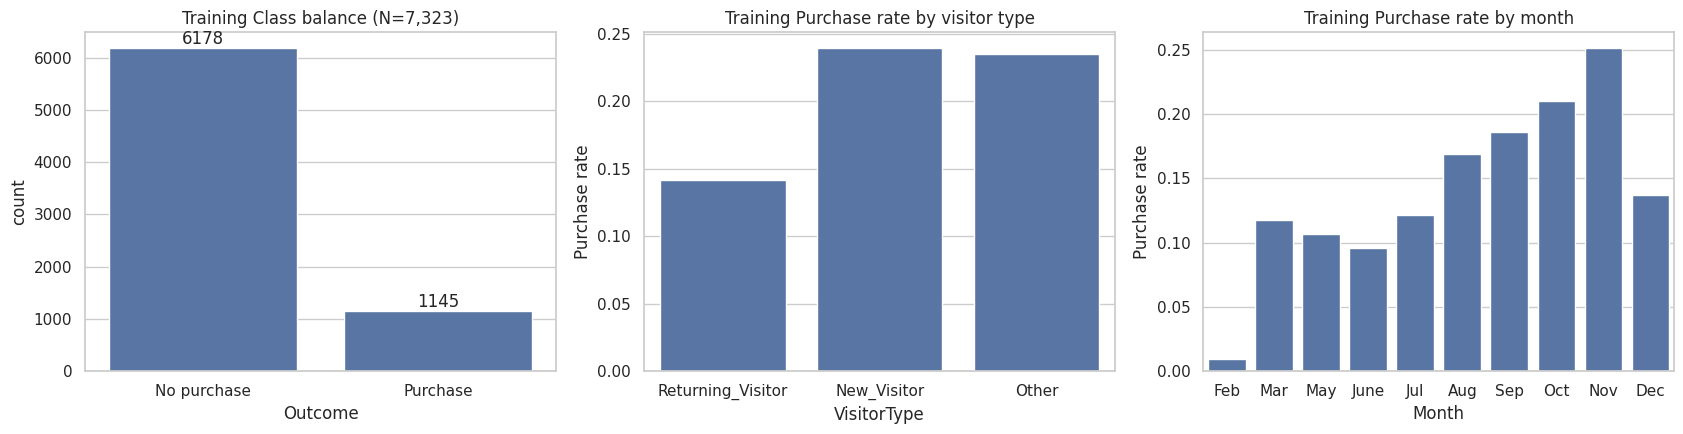

In [11]:
df_train = X_train.copy()
df_train["Revenue"] = y_train
df_train["Outcome"] = df_train["Revenue"].map({1: "Purchase", 0: "No purchase"})

eda_plot = df_train.sample(min(len(df_train), 50000), random_state=RANDOM_STATE) if len(df_train) > 50000 else df_train

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.countplot(data=eda_plot, x="Outcome", ax=axes[0], order=["No purchase", "Purchase"])
axes[0].set_title(f"Training Class balance (N={len(eda_plot):,})")
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

sns.barplot(data=eda_plot, x="VisitorType", y="Revenue", ax=axes[1], errorbar=None)
axes[1].set_title("Training Purchase rate by visitor type")
axes[1].set_ylabel("Purchase rate")

month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
valid_months = [m for m in month_order if m in eda_plot["Month"].unique()] + [m for m in eda_plot["Month"].unique() if m not in month_order]
sns.barplot(data=eda_plot, x="Month", y="Revenue", order=valid_months, ax=axes[2], errorbar=None)
axes[2].set_title("Training Purchase rate by month")
axes[2].set_ylabel("Purchase rate")

plt.tight_layout()
plt.show()


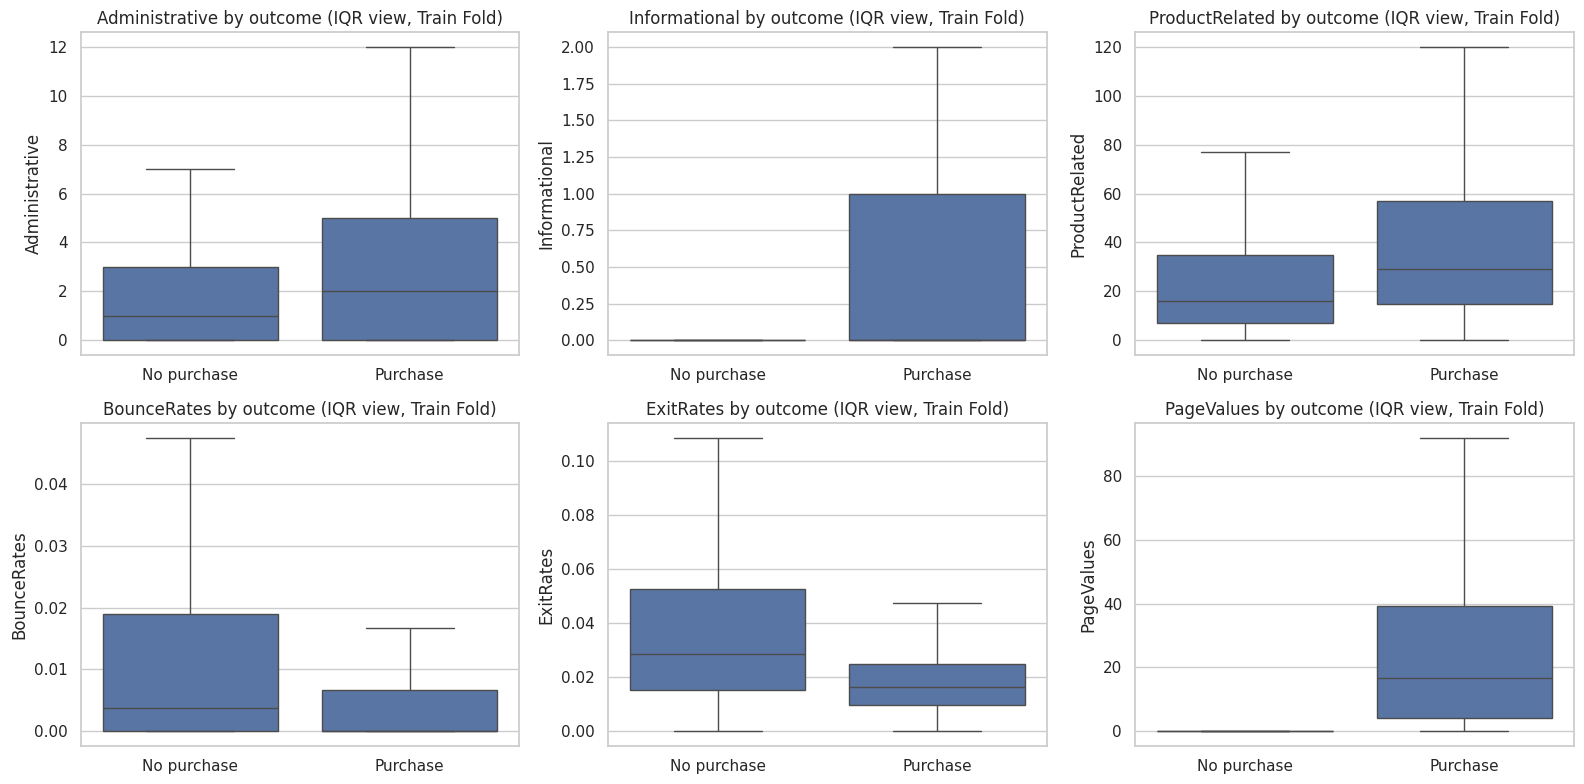

In [12]:
features_to_plot = ["Administrative", "Informational", "ProductRelated",
                    "BounceRates", "ExitRates", "PageValues"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feat in zip(axes.ravel(), features_to_plot):
    sns.boxplot(data=eda_plot, x="Outcome", y=feat, ax=ax, order=["No purchase", "Purchase"], showfliers=False)
    ax.set_title(f"{feat} by outcome (IQR view, Train Fold)")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()


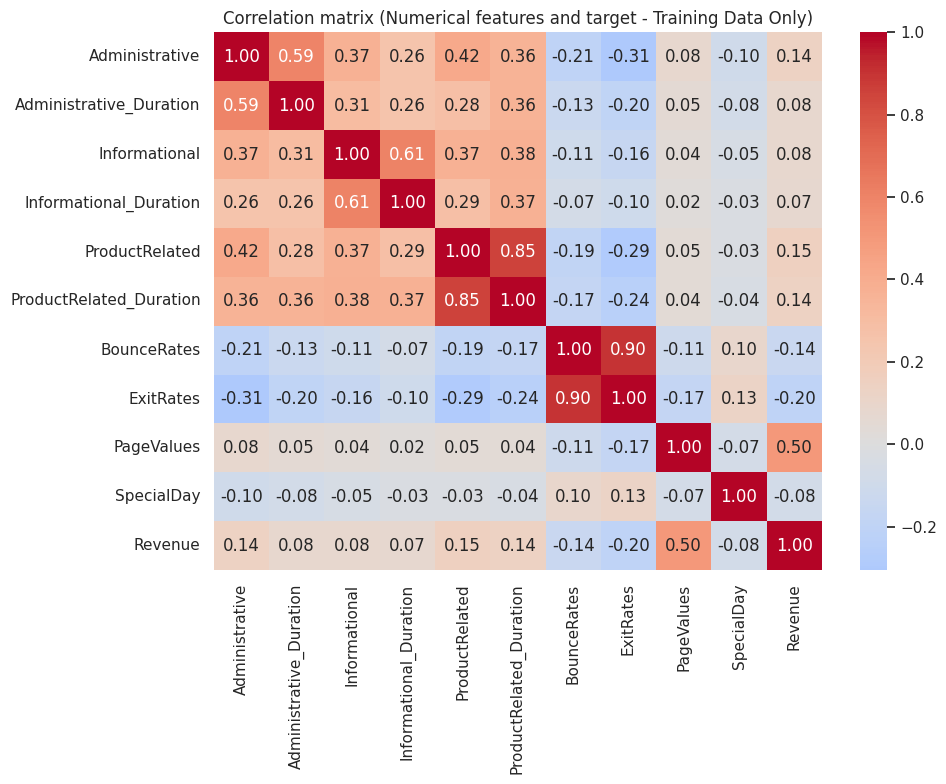

In [13]:
num_cols_corr = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
                 "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
                 "PageValues", "SpecialDay", "Revenue"]
plt.figure(figsize=(10, 8))
sns.heatmap(df_train[num_cols_corr].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (Numerical features and target - Training Data Only)")
plt.tight_layout()
plt.show()


**Analysis based on EDA**
- The target is imbalanced (~15.5% purchase rate); accuracy alone is misleading, so PR-AUC and F1 are primary evaluation criteria.
- `PageValues` strongly separates buyers from non-buyers; `BounceRates` and `ExitRates` are significantly higher for non-purchasers.
- New visitors show high conversion propensity, and November exhibits strong seasonal holiday volume lift.


# **7. Feature Engineering & Preprocessing Pipeline (Self-Contained in Notebook)**
We define `add_engineered_features` directly inside this notebook (no external `feature_utils.py` needed) and serialize bundles via `cloudpickle` so the function travels cleanly with the exported model.

Engineered domain features:
- **`Avg_Product_Duration`**: Average browsing duration per product item visited.
- **`Total_Pages`**: Cumulative session page count across admin, informational, and product URLs.
- **`Total_Duration`**: Aggregate active browsing time across the entire visit.
- **`Bounce_Exit_Ratio`** *(Full mode)*: Friction balance indicator (`ExitRates / (BounceRates + 0.001)`).
- **`PageValue_Per_Product`** *(Full mode)*: Commercial revenue potential per product interaction.

We use **`RobustScaler`** for continuous metrics (which scales via median and IQR, preventing skew distortion from outlier sessions) and **`OneHotEncoder`** with infrequent category pooling.


In [14]:
def add_engineered_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    prod = out.get("ProductRelated", 0)
    prod_dur = out.get("ProductRelated_Duration", 0.0)
    admin = out.get("Administrative", 0)
    admin_dur = out.get("Administrative_Duration", 0.0)
    info = out.get("Informational", 0)
    info_dur = out.get("Informational_Duration", 0.0)

    out["Avg_Product_Duration"] = prod_dur / (prod + 1.0)
    out["Total_Pages"] = admin + info + prod
    out["Total_Duration"] = admin_dur + info_dur + prod_dur

    if {"BounceRates", "ExitRates"}.issubset(out.columns):
        out["Bounce_Exit_Ratio"] = out["ExitRates"] / (out["BounceRates"] + 1e-3)

    if {"PageValues", "ProductRelated"}.issubset(out.columns):
        out["PageValue_Per_Product"] = out["PageValues"] / (prod + 1.0)
    return out

base_numeric_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration", "ProductRelated", "ProductRelated_Duration", "BounceRates",
                     "ExitRates", "PageValues", "SpecialDay"]
categorical_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
binary_cols = ["Weekend"]

# Features added by engineering
engineered_full_numeric = ["Avg_Product_Duration", "Total_Pages", "Total_Duration", "Bounce_Exit_Ratio", "PageValue_Per_Product"]
engineered_early_numeric = ["Avg_Product_Duration", "Total_Pages", "Total_Duration"]
numeric_cols = base_numeric_cols + engineered_full_numeric

# Reduced-feature session model
late_features = ["PageValues", "BounceRates", "ExitRates"]
early_numeric = [c for c in base_numeric_cols if c not in late_features] + engineered_early_numeric
def make_preprocessor(numeric=numeric_cols, scale_numeric=True):

    num_steps = [("imputer", SimpleImputer(strategy="median"))]

    if scale_numeric:
        num_steps.append(("scaler", RobustScaler()))

    num_step = Pipeline(steps=num_steps)
    cat_step = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10,
                                                                                                               sparse_output=False))])
    bin_step = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent"))])
    return ColumnTransformer([("num", num_step, numeric), ("cat", cat_step, categorical_cols), ("bin", bin_step, binary_cols)])

def make_pipeline(clf, use_smote=True, numeric=numeric_cols, scale_numeric=True):
    steps = [("feat_eng", FunctionTransformer(add_engineered_features, validate=False))]
    if use_smote:
        steps.append(("smotenc", SMOTENC(categorical_features=categorical_cols + binary_cols, random_state=RANDOM_STATE)))
    steps.append(("prep", make_preprocessor(numeric, scale_numeric=scale_numeric)))
    steps.append(("clf", clf))
    return Pipeline(steps)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
def cv_mean_std(search):
    idx = search.best_index_
    return float(search.cv_results_["mean_test_score"][idx]), float(search.cv_results_["std_test_score"][idx])


# **8. Evaluation Helper**


In [15]:
def evaluate(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {"Model": name, "PR-AUC": average_precision_score(y_true, prob), "ROC-AUC": roc_auc_score(y_true, prob),
            "Precision": precision_score(y_true, pred, zero_division=0), "Recall": recall_score(y_true, pred, zero_division=0), "F1": f1_score(y_true, pred, zero_division=0),
            "Accuracy": accuracy_score(y_true, pred),}

baseline_pr = y_val.mean()
print(f"No-skill PR-AUC baseline (purchase rate in validation set): {baseline_pr:.3f}")

No-skill PR-AUC baseline (purchase rate in validation set): 0.156


# **9. Baselines (no resampling)**


In [16]:
results = []
fitted = {}

for name, clf in [("LR (baseline)", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)), ("kNN k=5 (baseline)", KNeighborsClassifier(n_neighbors=5))]:
    pipe = make_pipeline(clf, use_smote=False)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    results.append(evaluate(name, y_val, pipe.predict_proba(X_val)[:, 1]))

pd.DataFrame(results).round(4)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
0,LR (baseline),0.6228,0.8824,0.7110,0.4068,0.5175,0.8816
1,kNN k=5 (baseline),0.5275,0.8420,0.6275,0.5039,0.5590,0.8759


# **10. SMOTE + Logistic Regression and k-NN (tuned)**


In [17]:
# Hyperparameter tuning for SMOTE + Logistic Regression and k-NN
searches={"LR + SMOTE": GridSearchCV(estimator=make_pipeline(LogisticRegression( max_iter=3000, random_state=RANDOM_STATE)), param_grid={ "clf__C": [0.01, 0.1, 1, 10, 100]},
                                     scoring="average_precision", cv=cv, n_jobs=-1),
          "kNN + SMOTE": GridSearchCV(estimator=make_pipeline(KNeighborsClassifier()), param_grid={"clf__n_neighbors": [5, 15, 31, 51],
                                                                                                   "clf__weights": ["uniform", "distance"]}, scoring="average_precision",
                                      cv=cv, n_jobs=-1)}


# Preserve models from previous experiments
if "experiment_models" not in globals():
    experiment_models = {}

# Store results for both tuned models
for name, gs in searches.items():
    print(f"Training {name}...")

    # 1. Hyperparameter tuning using training data
    gs.fit(X_train, y_train)
    best_model = gs.best_estimator_

    # Store fitted model
    fitted[name] = best_model

    # 2. Retrieve best cross-validation PR-AUC
    mean_pr, std_pr = cv_mean_std(gs)

    # 3. Generate out-of-fold probabilities on training data
    oof_prob = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

    # 4. Select optimal classification threshold using OOF predictions
    p_c, r_c, thr_c = precision_recall_curve(y_train, oof_prob)
    f1_c = (2 * p_c[:-1] * r_c[:-1] / (p_c[:-1] + r_c[:-1] + 1e-12))
    best_t = float(thr_c[np.argmax(f1_c)])

    # 5. Generate validation probabilities
    v_prob = best_model.predict_proba(X_val)[:, 1]

    # 6. Evaluate using the OOF-selected threshold
    val_metrics = evaluate(name, y_val, v_prob, threshold=best_t)
    results.append(val_metrics)

    # 7. Save model, threshold and tuning information
    experiment_models[f"Full - {name}"] = {"model": best_model, "threshold": best_t, "params": gs.best_params_, "cv_pr_auc": mean_pr, "cv_std": std_pr,
                                           "oof_pr_auc": average_precision_score(y_train, oof_prob)}

    # 8. Display results
    print("Best parameters:", gs.best_params_)
    print(f"CV PR-AUC: {mean_pr:.4f} ± {std_pr:.4f}")
    print(f"OOF PR-AUC: {average_precision_score(y_train, oof_prob):.4f}")
    print(f"Selected threshold: {best_t:.4f}")
    print(f"Validation PR-AUC: {val_metrics['PR-AUC']:.4f}")
    print(f"Validation Precision: {val_metrics['Precision']:.4f}")
    print(f"Validation Recall: {val_metrics['Recall']:.4f}")
    print(f"Validation F1: {val_metrics['F1']:.4f}")


# 9. Display comparison of tuned models
tuned_results = pd.DataFrame([r for r in results if r["Model"] in searches])
print("\nTuned SMOTE Model Comparison:")
display(tuned_results.set_index("Model").round(4))

Training LR + SMOTE...
Best parameters: {'clf__C': 0.01}
CV PR-AUC: 0.6514 ± 0.0248
OOF PR-AUC: 0.6475
Selected threshold: 0.5611
Validation PR-AUC: 0.6130
Validation Precision: 0.5801
Validation Recall: 0.6273
Validation F1: 0.6028
Training kNN + SMOTE...
Best parameters: {'clf__n_neighbors': 51, 'clf__weights': 'distance'}
CV PR-AUC: 0.6122 ± 0.0093
OOF PR-AUC: 0.6105
Selected threshold: 0.6491
Validation PR-AUC: 0.6230
Validation Precision: 0.4739
Validation Recall: 0.6903
Validation F1: 0.5620

Tuned SMOTE Model Comparison:


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
LR + SMOTE,0.613,0.8581,0.5801,0.6273,0.6028,0.871
kNN + SMOTE,0.623,0.8629,0.4739,0.6903,0.5620,0.832


# **11. Class-weighted Logistic Regression**


In [19]:
# Preserve models from previous experiments
if "experiment_models" not in globals():
    experiment_models = {}

# Initialize fitted models and results if required
if "fitted" not in globals():
    fitted = {}

if "results" not in globals():
    results = []


# 1. Define Logistic Regression with class weighting
cw_search = GridSearchCV(estimator=make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE), use_smote=False),
                         param_grid={"clf__C": [0.01, 0.1, 1, 10, 100]}, scoring="average_precision", cv=cv, n_jobs=-1, refit=True)


# 2. Hyperparameter tuning using training data
print("Training Class-weighted Logistic Regression...")
cw_search.fit(X_train, y_train)
best_model = cw_search.best_estimator_
name = "LR + class weights"

# Store fitted model
fitted[name] = best_model


# 3. Retrieve best cross-validation PR-AUC
mean_pr, std_pr = cv_mean_std(cw_search)


# 4. Generate out-of-fold probabilities on training data
oof_prob = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]


# 5. Select optimal classification threshold using OOF predictions
p_c, r_c, thr_c = precision_recall_curve(y_train, oof_prob)
f1_c = (2 * p_c[:-1] * r_c[:-1] / (p_c[:-1] + r_c[:-1] + 1e-12))
best_t = float(thr_c[np.argmax(f1_c)])


# 6. Generate validation probabilities
v_prob = best_model.predict_proba(X_val)[:, 1]


# 7. Evaluate using the selected threshold
val_metrics = evaluate(name, y_val, v_prob, threshold=best_t)
results.append(val_metrics)


# 8. Store model and experiment information
experiment_models[f"Full - {name}"] = {"model": best_model, "threshold": best_t, "params": cw_search.best_params_, "cv_pr_auc": mean_pr, "cv_std": std_pr,
                                       "oof_pr_auc": average_precision_score(y_train, oof_prob)}


# 9. Display results
print("\nClass-weighted Logistic Regression Results")
print("Best parameters:", cw_search.best_params_)
print(f"CV PR-AUC: {mean_pr:.4f} ± {std_pr:.4f}")
print(f"OOF PR-AUC: {average_precision_score(y_train, oof_prob):.4f}")
print(f"Selected threshold: {best_t:.4f}")
print(f"Validation PR-AUC: {val_metrics['PR-AUC']:.4f}")
print(f"Validation ROC-AUC: {val_metrics['ROC-AUC']:.4f}")
print(f"Validation Precision: {val_metrics['Precision']:.4f}")
print(f"Validation Recall: {val_metrics['Recall']:.4f}")
print(f"Validation F1: {val_metrics['F1']:.4f}")
print(f"Validation Accuracy: {val_metrics['Accuracy']:.4f}")


# 10. Display classification report
val_pred = (v_prob >= best_t).astype(int)

print("\nValidation Classification Report:")
print(classification_report(y_val, val_pred, zero_division=0))

Training Class-weighted Logistic Regression...

Class-weighted Logistic Regression Results
Best parameters: {'clf__C': 0.01}
CV PR-AUC: 0.6792 ± 0.0199
OOF PR-AUC: 0.6761
Selected threshold: 0.5359
Validation PR-AUC: 0.6172
Validation ROC-AUC: 0.8928
Validation Precision: 0.5705
Validation Recall: 0.6903
Validation F1: 0.6247
Validation Accuracy: 0.8705

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.90      0.92      2060
           1       0.57      0.69      0.62       381

    accuracy                           0.87      2441
   macro avg       0.76      0.80      0.77      2441
weighted avg       0.88      0.87      0.88      2441



# **12. Ensembling: Soft Voting & Stacking (Meta-Learner Architecture)**
We keep **Soft Voting (`VotingClassifier`)** alongside **true Stacking (`StackingClassifier`)**. Stacking trains base models and uses cross-validated base probability predictions as features for a secondary meta-classifier (`LogisticRegression`), which learns which base model to trust for each visitor profile.


In [20]:
experiment_models = globals().get("experiment_models", {})
voting_model = VotingClassifier(estimators=[("lr_cw", cw_search.best_estimator_), ("knn_smote", searches["kNN + SMOTE"].best_estimator_)], voting="soft", weights=[1, 1],
                                n_jobs=-1)
voting_model.fit(X_train, y_train)
fitted["Soft Voting (LR + kNN)"] = voting_model
vote_val_prob = voting_model.predict_proba(X_val)[:, 1]
results.append(evaluate("Soft Voting (LR + kNN)", y_val, vote_val_prob))

vote_oof_prob = cross_val_predict(voting_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
vote_cv_pr = float(average_precision_score(y_train, vote_oof_prob))
p_v, r_v, thr_v = precision_recall_curve(y_train, vote_oof_prob)
f1_v = (2 * p_v[:-1] * r_v[:-1] / (p_v[:-1] + r_v[:-1] + 1e-12))

vote_best_t = float(thr_v[np.argmax(f1_v)])
experiment_models["Full - Soft Voting (LR + kNN)"] = {"model": voting_model, "threshold": vote_best_t, "params": {"voting": "soft", "weights": [1, 1]},
                                                      "cv_pr_auc": vote_cv_pr, "cv_std": 0.0,}

stacking_model = StackingClassifier(estimators=[("lr_cw", cw_search.best_estimator_), ("knn_smote", searches["kNN + SMOTE"].best_estimator_)],
                                    final_estimator=LogisticRegression(random_state=RANDOM_STATE), cv=3, n_jobs=-1)
stacking_model.fit(X_train, y_train)
fitted["Stacking (LR + kNN)"] = stacking_model
stack_val_prob = stacking_model.predict_proba(X_val)[:, 1]
results.append(evaluate("Stacking (LR + kNN)", y_val, stack_val_prob))
stack_oof_prob = cross_val_predict(stacking_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
stack_cv_pr = float(average_precision_score(y_train, stack_oof_prob))
p_s, r_s, thr_s = precision_recall_curve(y_train, stack_oof_prob)
f1_s = (2 * p_s[:-1] * r_s[:-1] / (p_s[:-1] + r_s[:-1] + 1e-12))

stack_best_t = float(thr_s[np.argmax(f1_s)])
experiment_models["Full - Stacking (LR + kNN)"] = {"model": stacking_model, "threshold": stack_best_t, "params": {"final_estimator": "LogisticRegression", "cv": 3},
                                                   "cv_pr_auc": stack_cv_pr, "cv_std": 0.0,}

print("Validation metrics for Soft Voting and Stacking Models (evaluated on X_val):")
display(pd.DataFrame(results[-2:]).set_index("Model").round(4))

Validation metrics for Soft Voting and Stacking Models (evaluated on X_val):


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
Soft Voting (LR + kNN),0.6474,0.8849,0.4672,0.7664,0.5805,0.8271
Stacking (LR + kNN),0.6426,0.8926,0.6548,0.5328,0.5876,0.8832


# **13. Model Comparison on Validation Partition**


In [21]:
results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4).sort_values("PR-AUC", ascending=False))
print(f"(No-skill PR-AUC baseline = {baseline_pr:.3f})")


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
Soft Voting (LR + kNN),0.6474,0.8849,0.4672,0.7664,0.5805,0.8271
Stacking (LR + kNN),0.6426,0.8926,0.6548,0.5328,0.5876,0.8832
kNN + SMOTE,0.6230,0.8629,0.4739,0.6903,0.5620,0.8320
LR (baseline),0.6228,0.8824,0.7110,0.4068,0.5175,0.8816
LR + class weights,0.6172,0.8928,0.5705,0.6903,0.6247,0.8705
LR + SMOTE,0.6130,0.8581,0.5801,0.6273,0.6028,0.8710
kNN k=5 (baseline),0.5275,0.8420,0.6275,0.5039,0.5590,0.8759


(No-skill PR-AUC baseline = 0.156)


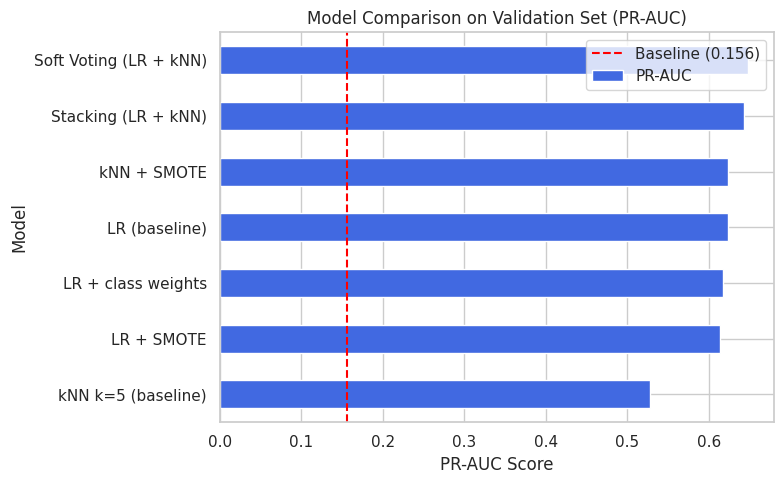

In [22]:
plt.figure(figsize=(8, 5))
results_df["PR-AUC"].sort_values().plot(kind="barh", color="royalblue")
plt.axvline(baseline_pr, color="red", linestyle="--", label=f"Baseline ({baseline_pr:.3f})")
plt.title("Model Comparison on Validation Set (PR-AUC)")
plt.xlabel("PR-AUC Score")
plt.legend()
plt.tight_layout()
plt.show()

**Note:** Model performance is evaluated using validation predictions. Probability thresholds are calibrated using out-of-fold predictions on the training partition. PR-AUC is calculated independently of the selected classification threshold.

# **14. Baseline Model: Out-of-Fold Threshold Tuning**
To avoid optimistic circular evaluation, we select the operating threshold using **out-of-fold cross-validated predictions on the training set (`X_train`)**, ensuring the validation set (`X_val`) remains an unbiased evaluator.


In [23]:
# Include all candidate baseline models in selection
candidates = {"LR + SMOTE": searches["LR + SMOTE"].best_score_, "kNN + SMOTE": searches["kNN + SMOTE"].best_score_, "LR + class weights": cw_search.best_score_,}
final_name = max(candidates, key=candidates.get)
final_model = fitted[final_name]
print(f"Selected baseline candidate: {final_name} | CV PR-AUC: {candidates[final_name]:.4f}")

# Generate out-of-fold training probabilities using cross_val_predict
oof_prob = cross_val_predict(final_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# Tune threshold on training out-of-fold predictions
prec, rec, thr = precision_recall_curve(y_train, oof_prob)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = float(thr[np.argmax(f1s)])
print(f"Out-of-fold training threshold maximizing F1: {best_threshold:.3f} (OOF F1 = {f1s.max():.3f})")

Selected baseline candidate: LR + class weights | CV PR-AUC: 0.6792
Out-of-fold training threshold maximizing F1: 0.536 (OOF F1 = 0.662)


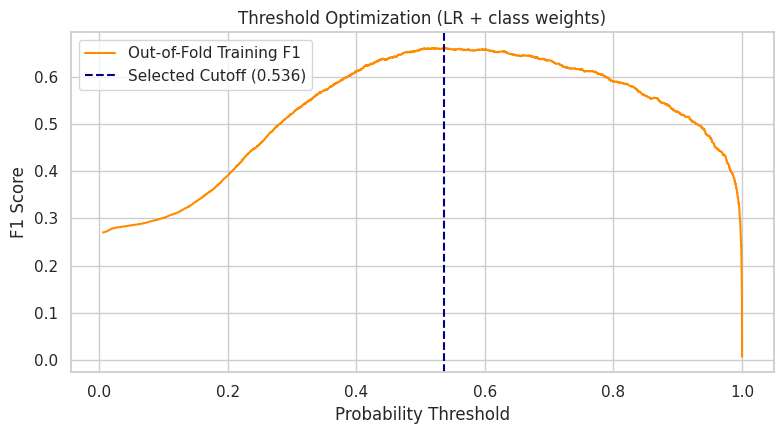

In [24]:
plt.figure(figsize=(8, 4.5))
plt.plot(thr, f1s, color="darkorange", label="Out-of-Fold Training F1")
plt.axvline(best_threshold, color="navy", linestyle="--", label=f"Selected Cutoff ({best_threshold:.3f})")
plt.xlabel("Probability Threshold")
plt.ylabel("F1 Score")
plt.title(f"Threshold Optimization ({final_name})")
plt.legend()
plt.tight_layout()
plt.show()


# **15. Baseline Model Validation (at Tuned Threshold)**


In [25]:
val_prob = final_model.predict_proba(X_val)[:, 1]
val_pred = (val_prob >= best_threshold).astype(int)

final_row = evaluate(f"{final_name} @ {best_threshold:.2f}", y_val, val_prob, best_threshold)
display(pd.DataFrame([final_row]).set_index("Model").round(4))

print("VALIDATION SET CLASSIFICATION REPORT:")
print(classification_report(y_val, val_pred, target_names=["No purchase", "Purchase"], zero_division=0))

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy
Model,,,,,,
LR + class weights @ 0.54,0.6172,0.8928,0.5705,0.6903,0.6247,0.8705


VALIDATION SET CLASSIFICATION REPORT:
              precision    recall  f1-score   support

 No purchase       0.94      0.90      0.92      2060
    Purchase       0.57      0.69      0.62       381

    accuracy                           0.87      2441
   macro avg       0.76      0.80      0.77      2441
weighted avg       0.88      0.87      0.88      2441



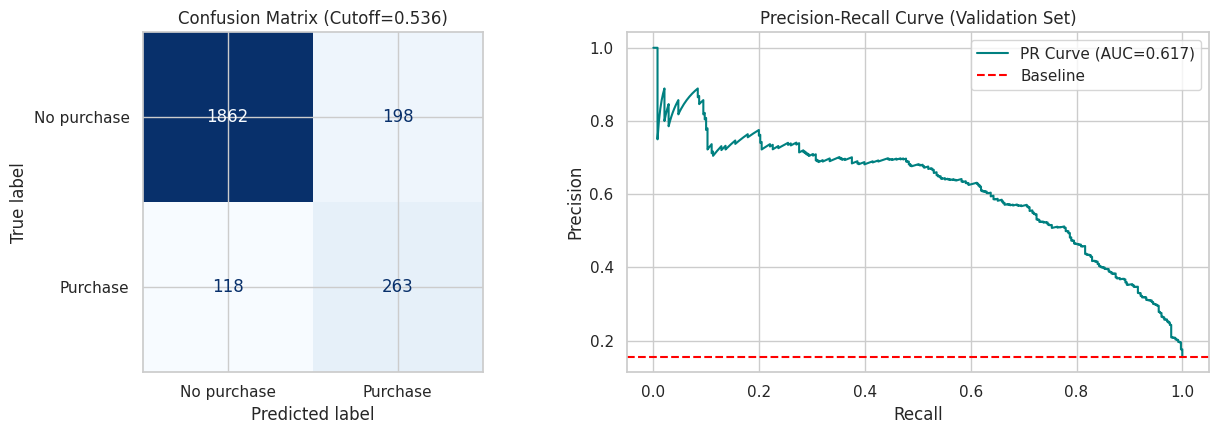

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=["No purchase", "Purchase"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion Matrix (Cutoff={best_threshold:.3f})")

p_val, r_val, _ = precision_recall_curve(y_val, val_prob)
axes[1].plot(r_val, p_val, color="teal", label=f"PR Curve (AUC={average_precision_score(y_val, val_prob):.3f})")
axes[1].axhline(baseline_pr, color="red", linestyle="--", label="Baseline")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve (Validation Set)")
axes[1].legend()

plt.tight_layout()
plt.show()

# **16. Baseline Interpretation: Logistic Regression Coefficients**


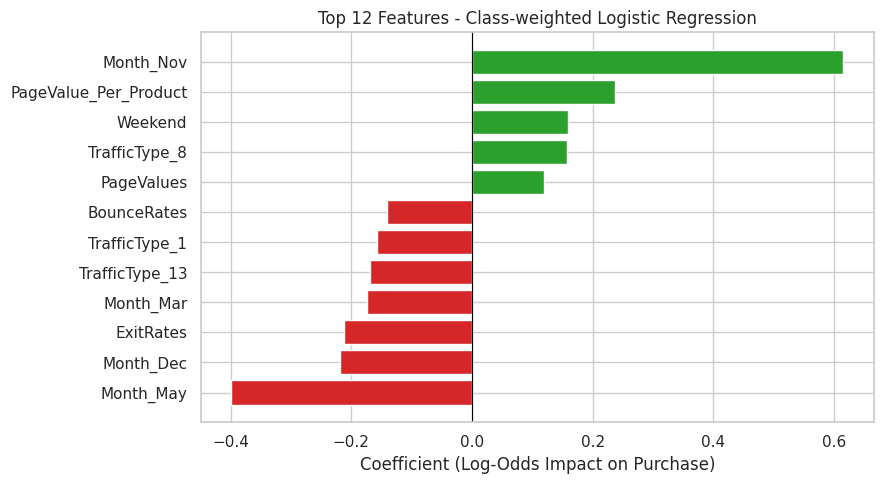

In [27]:
# Feature importance from Logistic Regression
if "LR + class weights" in fitted:
    lr_pipe = fitted["LR + class weights"]
    model_title = "Class-weighted Logistic Regression"

elif "LR + SMOTE" in fitted:
    lr_pipe = fitted["LR + SMOTE"]
    model_title = "SMOTE Logistic Regression"

else:
    raise KeyError("Neither 'LR + class weights' nor 'LR + SMOTE' was found in the fitted dictionary.")

feature_names = lr_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"Feature": feature_names, "Coefficient": lr_pipe.named_steps["clf"].coef_[0]})
coefs["Feature"] = coefs["Feature"].str.replace(r"^(num|cat|bin)__", "", regex=True)
coefs["abs"] = coefs["Coefficient"].abs()
top = (coefs.sort_values("abs", ascending=False).head(12).sort_values("Coefficient"))

# Plot top 12 features
plt.figure(figsize=(9, 5))
colors = ["tab:red" if c < 0 else "tab:green" for c in top["Coefficient"]]
plt.barh(top["Feature"], top["Coefficient"], color=colors)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (Log-Odds Impact on Purchase)")
plt.title("Top 12 Features - " + model_title)

plt.tight_layout()
plt.show()

The coefficients show the log-odds change per unit scaled feature (for continuous variables) or relative to the global regularized intercept (for one-hot encoded dummy variables). Features like `PageValue_Per_Product` and `PageValues` exert the strongest positive influence, while high `BounceRates` depress purchase likelihood.


# **17. Reduced-Feature Model Ablation**
We evaluate model performance after removing PageValues, BounceRates,
ExitRates and their derivatives.



========== Full FEATURE MODEL ==========
Best parameters: {'clf__C': 0.01}
CV PR-AUC: 0.6792 ± 0.0199
OOF PR-AUC: 0.6761
Selected threshold: 0.5359
Validation PR-AUC: 0.6172
Validation Precision: 0.5705
Validation Recall: 0.6903
Validation F1: 0.6247
Validation Accuracy: 0.8705

========== Early FEATURE MODEL ==========
Best parameters: {'clf__C': 0.1}
CV PR-AUC: 0.2896 ± 0.0079
OOF PR-AUC: 0.2857
Selected threshold: 0.4714
Validation PR-AUC: 0.2993
Validation Precision: 0.2627
Validation Recall: 0.7218
Validation F1: 0.3852
Validation Accuracy: 0.6403
========== FULL VS REDUCED FEATURE COMPARISON ==========


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,CV PR-AUC,CV Std,OOF PR-AUC,Threshold
Model,,,,,,,,,,
Full Features - LR Class Weight,0.6172,0.8928,0.5705,0.6903,0.6247,0.8705,0.6792,0.0199,0.6761,0.5359
Reduced Features - LR Class Weight,0.2993,0.7328,0.2627,0.7218,0.3852,0.6403,0.2896,0.0079,0.2857,0.4714


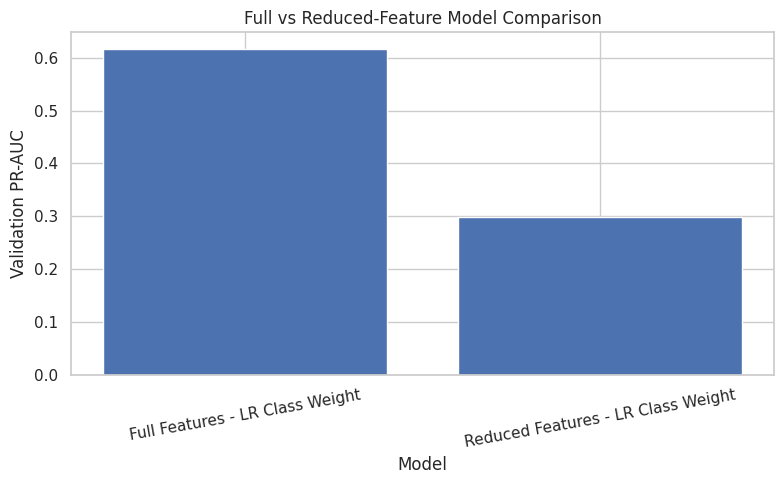


Features removed from Reduced-Feature Model:
- PageValues
- BounceRates
- ExitRates

Full model features: 17
Reduced model features: 14

Ablation experiment completed successfully.


In [28]:
# 1. Define the two feature sets
feature_sets_ablation = {"Full": (X_train, X_val, numeric_cols),"Early": ( X_train.drop(columns=late_features), X_val.drop(columns=late_features), early_numeric)}

# Preserve previously stored models
if "experiment_models" not in globals():
    experiment_models = {}

if "fitted" not in globals():
    fitted = {}

ablation_results = []
ablation_models = {}


# 2. Train and evaluate both models
for scope, (Xtr, Xv, num_cols) in feature_sets_ablation.items():

    print(f"\n========== {scope} FEATURE MODEL ==========")

    # Class-weighted Logistic Regression pipeline
    pipe = make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE), use_smote=False, numeric=num_cols)

    # Hyperparameter tuning
    search = GridSearchCV(estimator=pipe, param_grid={"clf__C": [0.01, 0.1, 1, 10, 100]}, scoring="average_precision", cv=cv, n_jobs=-1, refit=True)

    # Fit using training data only
    search.fit(Xtr, y_train)
    best_model = search.best_estimator_

    # Cross-validation PR-AUC
    mean_pr, std_pr = cv_mean_std(search)

    # 3. Generate training out-of-fold probabilities
    oof_prob = cross_val_predict(best_model, Xtr, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

    # 4. Select threshold using training OOF predictions
    p_c, r_c, thr_c = precision_recall_curve(y_train, oof_prob)
    f1_c = (2 * p_c[:-1] * r_c[:-1] / (p_c[:-1] + r_c[:-1] + 1e-12))
    best_t = float(thr_c[np.argmax(f1_c)])

    # 5. Generate validation probabilities
    val_prob_ablation = best_model.predict_proba(Xv)[:, 1]

    # 6. Evaluate on validation data
    model_name = ("Full Features - LR Class Weight" if scope == "Full" else "Reduced Features - LR Class Weight")
    val_metrics = evaluate(model_name, y_val, val_prob_ablation, best_t)

    # Add CV and threshold information
    val_metrics["CV PR-AUC"] = mean_pr
    val_metrics["CV Std"] = std_pr
    val_metrics["OOF PR-AUC"] = average_precision_score(y_train, oof_prob)
    val_metrics["Threshold"] = best_t
    ablation_results.append(val_metrics)

    # Store model information
    key = ("Full - LR + class weights (ablation)" if scope == "Full" else "Early - LR + class weights (reduced features)")
    ablation_models[scope] = {"model": best_model, "threshold": best_t, "params": search.best_params_, "cv_pr_auc": mean_pr, "cv_std": std_pr,
                              "oof_pr_auc": average_precision_score(y_train, oof_prob)}
    experiment_models[key] = ablation_models[scope]
    fitted[key] = best_model

    # Display individual model results
    print("Best parameters:", search.best_params_)
    print(f"CV PR-AUC: {mean_pr:.4f} ± {std_pr:.4f}")
    print(f"OOF PR-AUC: {average_precision_score(y_train, oof_prob):.4f}")
    print(f"Selected threshold: {best_t:.4f}")
    print(f"Validation PR-AUC: {val_metrics['PR-AUC']:.4f}")
    print(f"Validation Precision: {val_metrics['Precision']:.4f}")
    print(f"Validation Recall: {val_metrics['Recall']:.4f}")
    print(f"Validation F1: {val_metrics['F1']:.4f}")
    print(f"Validation Accuracy: {val_metrics['Accuracy']:.4f}")


# 7. Create comparison table
comparison = pd.DataFrame(ablation_results).set_index("Model")
print("========== FULL VS REDUCED FEATURE COMPARISON ==========")
display(comparison.round(4))


# 8. Visual comparison of validation PR-AUC
plt.figure(figsize=(8, 5))
plt.bar(comparison.index, comparison["PR-AUC"])
plt.ylabel("Validation PR-AUC")
plt.xlabel("Model")
plt.title("Full vs Reduced-Feature Model Comparison")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


# 9. Display feature removal information
print("\nFeatures removed from Reduced-Feature Model:")

for feature in late_features:
    print("-", feature)

print("\nFull model features:", X_train.shape[1])
print("Reduced model features:",X_train.drop(columns=late_features).shape[1])
print("\nAblation experiment completed successfully.")

# **18. Baseline Threshold: Business Interpretation**


In [29]:
rows = []
for t in sorted(set([0.3, 0.4, 0.5, 0.6, 0.7, round(float(best_threshold), 2)])):
    pred = (val_prob >= t).astype(int)
    rows.append({"Threshold":t, "Validation Flagged Buyers": int(pred.sum()), "Precision": precision_score(y_val, pred, zero_division=0), "Recall": recall_score(y_val, pred, zero_division=0),
                 "F1": f1_score(y_val, pred, zero_division=0)})
pd.DataFrame(rows).round(3).reset_index(drop=True)

,Threshold,Validation Flagged Buyers,Precision,Recall,F1
0,0.30,942,0.361,0.892,0.514
1,0.40,673,0.458,0.808,0.584
2,0.50,505,0.545,0.722,0.621
3,0.54,457,0.571,0.685,0.623
4,0.60,398,0.603,0.630,0.616
5,0.70,335,0.639,0.562,0.598


# **19. Tree-Based Model Experiments**



========== Full MODEL ==========

Training Random Forest (Full)...
Best parameters: {'clf__max_depth': 10, 'clf__min_samples_leaf': 5}
CV PR-AUC: 0.7594 ± 0.0142
OOF PR-AUC:0.7583
Selected threshold: 0.3601
Validation PR-AUC: 0.7296
Validation Precision: 0.5898
Validation Recall: 0.6982
Validation F1: 0.6394

Training Extra Trees (Full)...
Best parameters: {'clf__max_depth': 15, 'clf__min_samples_leaf': 2}
CV PR-AUC: 0.7186 ± 0.0167
OOF PR-AUC:0.7147
Selected threshold: 0.2613
Validation PR-AUC: 0.6767
Validation Precision: 0.6005
Validation Recall: 0.6982
Validation F1: 0.6456

Training HistGradientBoosting (Full)...
Best parameters: {'clf__learning_rate': 0.05, 'clf__max_iter': 100, 'clf__max_leaf_nodes': 15}
CV PR-AUC: 0.7533 ± 0.0162
OOF PR-AUC:0.7511
Selected threshold: 0.7111
Validation PR-AUC: 0.7217
Validation Precision: 0.6097
Validation Recall: 0.6929
Validation F1: 0.6486

========== Early MODEL ==========

Training Random Forest (Early)...
Best parameters: {'clf__max_depth

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,CV PR-AUC,CV Std,OOF PR-AUC,Threshold
Model,,,,,,,,,,
Full - Random Forest,0.7296,0.9171,0.5898,0.6982,0.6394,0.8771,0.7594,0.0142,0.7583,0.3601
Full - HistGradientBoosting,0.7217,0.9179,0.6097,0.6929,0.6486,0.8828,0.7533,0.0162,0.7511,0.7111
Full - Extra Trees,0.6767,0.9020,0.6005,0.6982,0.6456,0.8804,0.7186,0.0167,0.7147,0.2613
Early - Random Forest,0.3563,0.7550,0.3112,0.5302,0.3922,0.7435,0.3641,0.0183,0.3568,0.2021
Early - HistGradientBoosting,0.3440,0.7514,0.3244,0.5066,0.3955,0.7583,0.3490,0.0087,0.3453,0.5805
Early - Extra Trees,0.3576,0.7589,0.3310,0.4987,0.3979,0.7644,0.3475,0.0086,0.3427,0.2045


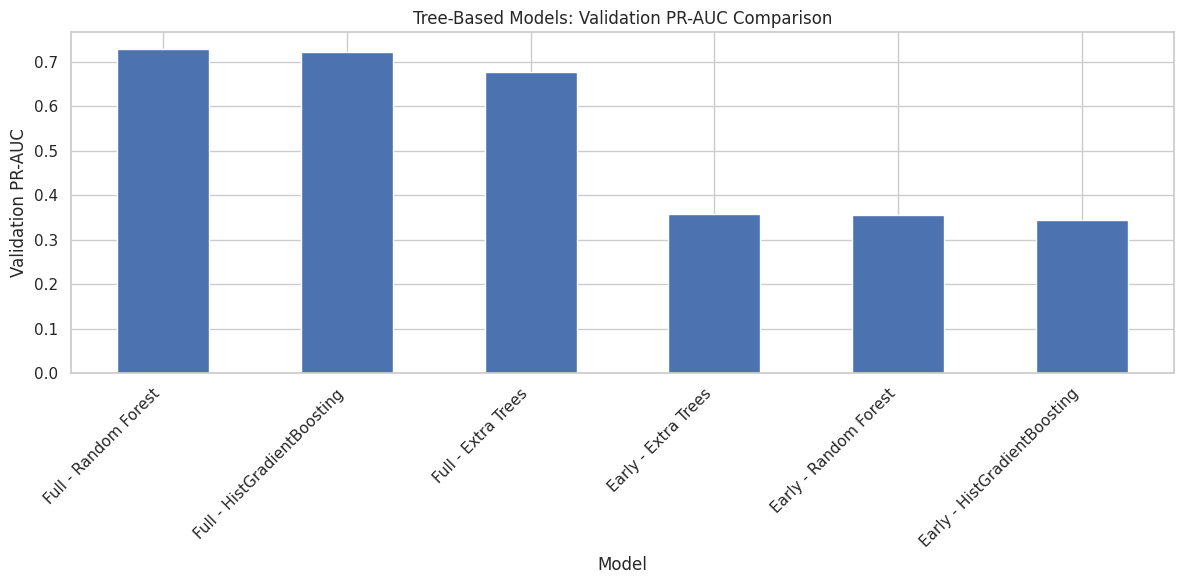


========== STORED MODEL CANDIDATES ==========
- Full - LR + SMOTE
- Full - kNN + SMOTE
- Full - LR + class weights
- Full - Soft Voting (LR + kNN)
- Full - Stacking (LR + kNN)
- Full - LR + class weights (ablation)
- Early - LR + class weights (reduced features)
- Full - Random Forest
- Full - Extra Trees
- Full - HistGradientBoosting
- Early - Random Forest
- Early - Extra Trees
- Early - HistGradientBoosting

Total models stored in experiment_models: 13


In [30]:
# 1. Define Full and Reduced-Feature datasets
feature_sets = {"Full": (X_train, X_val, numeric_cols), "Early":(X_train.drop(columns=late_features), X_val.drop(columns=late_features), early_numeric)}

# 2. Define tree-based model configurations
model_configs={"Random Forest":(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),{"clf__max_depth":[10, 15], "clf__min_samples_leaf":[2, 5]}),
               "Extra Trees":(ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),{"clf__max_depth": [10, 15], "clf__min_samples_leaf": [2, 5]}),
               "HistGradientBoosting":(HistGradientBoostingClassifier(random_state=RANDOM_STATE,class_weight="balanced"),{"clf__max_iter":[100, 150],
                                                                                                                          "clf__learning_rate":[0.05, 0.1],
                                                                                                                          "clf__max_leaf_nodes":[15, 31]})}


# 3. Initialize results

if "experiment_models" not in globals():
    experiment_models = {}

experiment_results = []


# 4. Train and evaluate each model
for scope, (Xtr, Xv, num_cols) in feature_sets.items():
    print(f"\n========== {scope} MODEL ==========")

    for model_name, (clf, params) in model_configs.items():
        print(f"\nTraining {model_name} ({scope})...")

        # Create preprocessing and model pipeline
        pipe = make_pipeline(clf, use_smote=False, numeric=num_cols, scale_numeric=False)

        # Hyperparameter tuning using 5-fold CV
        search = GridSearchCV(estimator=pipe, param_grid=params, scoring="average_precision", cv=cv, n_jobs=-1, refit=True)

        # Fit using training data only
        search.fit(Xtr, y_train)
        best_model = search.best_estimator_

        # 5. Obtain cross-validation PR-AUC
        mean_pr, std_pr = cv_mean_std(search)

        # 6. Generate training out-of-fold probabilities
        oof_prob = cross_val_predict(best_model, Xtr, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

        # 7. Select threshold using training OOF predictions
        p_c, r_c, thr_c = precision_recall_curve(y_train, oof_prob)
        f1_c = (2 * p_c[:-1] * r_c[:-1] / (p_c[:-1] + r_c[:-1] + 1e-12))
        best_t = float(thr_c[np.argmax(f1_c)])

        # 8. Generate validation probabilities
        v_prob = best_model.predict_proba(Xv)[:, 1]

        # 9. Evaluate using the selected threshold
        key = f"{scope} - {model_name}"
        row = evaluate(key, y_val, v_prob, best_t)

        row["CV PR-AUC"] = mean_pr
        row["CV Std"] = std_pr
        row["OOF PR-AUC"] = average_precision_score(y_train, oof_prob)
        row["Threshold"] = best_t
        experiment_results.append(row)

        # 10. Store model and experiment information
        experiment_models[key] = {"model": best_model, "threshold": best_t, "params": search.best_params_, "cv_pr_auc": mean_pr, "cv_std": std_pr,
                                  "oof_pr_auc": average_precision_score(y_train, oof_prob)}

        # 11. Display individual model results
        print("Best parameters:", search.best_params_)
        print(f"CV PR-AUC: {mean_pr:.4f} ± {std_pr:.4f}")
        print(f"OOF PR-AUC:{average_precision_score(y_train, oof_prob):.4f}")
        print(f"Selected threshold: {best_t:.4f}")
        print(f"Validation PR-AUC: {row['PR-AUC']:.4f}")
        print(f"Validation Precision: {row['Precision']:.4f}")
        print(f"Validation Recall: {row['Recall']:.4f}")
        print(f"Validation F1: {row['F1']:.4f}")


# 12. Create combined results table
experiment_results_df = pd.DataFrame(experiment_results)
experiment_results_df = (experiment_results_df.set_index("Model").sort_values("CV PR-AUC", ascending=False))

print("\n========== TREE-BASED MODEL COMPARISON ==========")
display(experiment_results_df.round(4))


# 13. Visualize validation PR-AUC comparison
plt.figure(figsize=(12, 6))
experiment_results_df["PR-AUC"].sort_values(ascending=False).plot(kind="bar")
plt.title("Tree-Based Models: Validation PR-AUC Comparison")
plt.xlabel("Model")
plt.ylabel("Validation PR-AUC")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# 14. Verify stored candidates
print("\n========== STORED MODEL CANDIDATES ==========")

for key in experiment_models:
    print("-", key)

print("\nTotal models stored in experiment_models:", len(experiment_models))

# **20. Boosted-Tree Imbalance Comparison (SMOTE vs. Class Weighting)**


In [31]:
xgb_results = []
xgb_models = {}

base_params = {"clf__n_estimators": randint(150, 350), "clf__max_depth": randint(3, 7), "clf__learning_rate": loguniform(0.02, 0.15), "clf__min_child_weight": randint(1, 8),
               "clf__subsample": uniform(0.7, 0.3), "clf__colsample_bytree": uniform(0.7, 0.3), "clf__reg_lambda": loguniform(0.1, 10), "clf__gamma": [0, 0.1, 0.3]}

for scope, (Xtr, Xv, num_cols) in feature_sets.items():
    for strategy in ["Class Weight", "SMOTE"]:
        print(f"\n{scope} XGBoost - {strategy}")
        if strategy == "SMOTE":
            param_dist = [{**base_params, "clf__scale_pos_weight": [1]}]
            use_smote = True
        else:
            # Empirical ratio is ~5.45 negative:positive
            param_dist = [{**base_params, "clf__scale_pos_weight": [3, 5.45, 7]}]
            use_smote = False


Full XGBoost - Class Weight

Full XGBoost - SMOTE

Early XGBoost - Class Weight

Early XGBoost - SMOTE


In [32]:
xgb = XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=RANDOM_STATE, n_jobs=1)
pipe = make_pipeline(xgb, use_smote=use_smote, numeric=num_cols, scale_numeric=False)
search = RandomizedSearchCV(estimator=pipe, param_distributions=param_dist, n_iter=10, scoring="average_precision", cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
search.fit(Xtr, y_train)
best_model = search.best_estimator_
mean_pr, std_pr = cv_mean_std(search)

       # Training OOF predictions
oof_prob = cross_val_predict(best_model, Xtr, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

# Optimize threshold on training OOF predictions
p_c, r_c, thr_c = precision_recall_curve(y_train, oof_prob)
f1_c = (2 * p_c[:-1] * r_c[:-1] / (p_c[:-1] + r_c[:-1] + 1e-12))
best_t = float(thr_c[np.argmax(f1_c)])

# Validation predictions
v_prob = best_model.predict_proba(Xv)[:, 1]
res = evaluate(f"{scope} XGBoost - {strategy}", y_val, v_prob, best_t)
res["CV PR-AUC"] = mean_pr
res["CV Std"] = std_pr
res["Threshold"] = best_t
xgb_results.append(res)
key = f"{scope} - XGBoost - {strategy}"
xgb_models[key] = {"model": best_model, "threshold": best_t, "params": search.best_params_, "cv_pr_auc": mean_pr, "cv_std": std_pr}
print(f"Best params: {search.best_params_}")
print(f"CV PR-AUC: {mean_pr:.4f} ± {std_pr:.4f} | Cutoff: {best_t:.3f} | Val F1: {res['F1']:.4f}")

display(pd.DataFrame(xgb_results).set_index("Model").round(4).sort_values("CV PR-AUC", ascending=False))

Best params: {'clf__colsample_bytree': np.float64(0.7587948587257435), 'clf__gamma': 0, 'clf__learning_rate': np.float64(0.13871211754929347), 'clf__max_depth': 3, 'clf__min_child_weight': 5, 'clf__n_estimators': 231, 'clf__reg_lambda': np.float64(1.200561092619211), 'clf__scale_pos_weight': 1, 'clf__subsample': np.float64(0.8760253496991544)}
CV PR-AUC: 0.3059 ± 0.0069 | Cutoff: 0.408 | Val F1: 0.3612


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,CV PR-AUC,CV Std,Threshold
Model,,,,,,,,,
Early XGBoost - SMOTE,0.3113,0.7199,0.2848,0.4934,0.3612,0.7276,0.3059,0.0069,0.4084


# **21. Final Candidate Selection, Test Set Evaluation and Model Export**
We compare **all evaluated models** across both standard tree ensembles and boosted trees. The selected winning models are evaluated once on the **untouched final test set (`X_test`)** and serialized using `cloudpickle` so no external `feature_utils.py` file is required.


========== SELECTED FINAL CANDIDATES ==========
Full Model: Full - Random Forest
 CV PR-AUC: 0.7594 ± 0.0142

Early Model: Early - Random Forest
 CV PR-AUC: 0.3641 ± 0.0183

========== FINAL TEST SET COMPARISON ==========


,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Threshold
Model,,,,,,,
Full -- Random Forest,0.7516,0.9309,0.6425,0.7435,0.6893,0.8951,0.3601
Early -- Random Forest,0.3583,0.7683,0.3232,0.5838,0.4160,0.7435,0.2021



=== FINAL TEST SET CLASSIFICATION REPORT (FULL MODEL) ===
              precision    recall  f1-score   support

 No purchase       0.95      0.92      0.94      2059
    Purchase       0.64      0.74      0.69       382

    accuracy                           0.90      2441
   macro avg       0.80      0.83      0.81      2441
weighted avg       0.90      0.90      0.90      2441


=== FINAL TEST SET CLASSIFICATION REPORT (EARLY MODEL) ===
              precision    recall  f1-score   support

 No purchase       0.91      0.77      0.84      2059
    Purchase       0.32      0.58      0.42       382

    accuracy                           0.74      2441
   macro avg       0.62      0.68      0.63      2441
weighted avg       0.82      0.74      0.77      2441



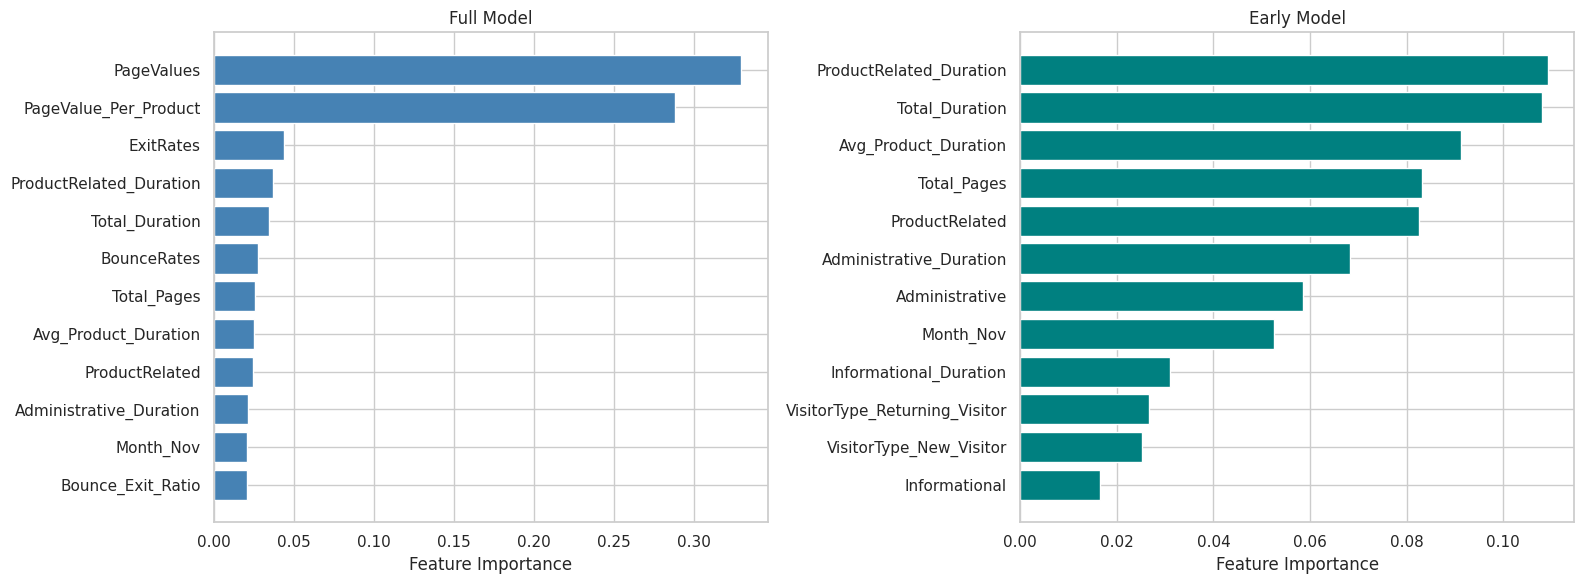


========== MODEL EXPORT COMPLETED ==========
Saved: shopper_model.joblib
Saved: shopper_model_bundle.joblib

Selected Full Model: Full - Random Forest
Full Model Threshold: 0.3601

Selected Early Model: Early - Random Forest
Early Model Threshold: 0.2021


In [33]:
# 1. Collect all available candidate models
experiment_candidates = globals().get("experiment_models", {})
boosted_candidates = globals().get("xgb_models", {})
all_candidates = {**experiment_candidates, **boosted_candidates}

# Keep only candidates with the information required for selection
valid_candidates={key:value for key, value in all_candidates.items() if isinstance(value, dict) and all(k in value for k in ["model", "threshold", "cv_pr_auc", "cv_std"])}

if not valid_candidates:
    raise ValueError("No valid candidate models found. Run the earlier model experiment sections first.")

# 2. Select the best Full and Early candidates using CV PR-AUC
full_candidates = {key: value for key, value in valid_candidates.items() if key.startswith("Full - ")}
early_candidates = {key: value for key, value in valid_candidates.items() if key.startswith("Early - ")}

if not full_candidates:
    raise ValueError("No Full-feature candidate models were found.")

if not early_candidates:
    raise ValueError("No Early-feature candidate models were found.")

full_key = max(full_candidates, key=lambda key: full_candidates[key]["cv_pr_auc"])
early_key = max(early_candidates, key=lambda key: early_candidates[key]["cv_pr_auc"])

print("========== SELECTED FINAL CANDIDATES ==========")

print(f"Full Model: {full_key}\n CV PR-AUC: {valid_candidates[full_key]['cv_pr_auc']:.4f} ± {valid_candidates[full_key]['cv_std']:.4f}")
print(f"\nEarly Model: {early_key}\n CV PR-AUC: {valid_candidates[early_key]['cv_pr_auc']:.4f} ± {valid_candidates[early_key]['cv_std']:.4f}")

# 3. Retrieve the selected models and their thresholds
full_model = valid_candidates[full_key]["model"]
full_threshold = float(valid_candidates[full_key]["threshold"])
early_model = valid_candidates[early_key]["model"]
early_threshold = float(valid_candidates[early_key]["threshold"])

# 4. Prepare the Early-feature test set
X_test_early = X_test.drop(columns=late_features, errors="ignore")

# 5. FINAL TEST SET EVALUATION
full_prob = full_model.predict_proba(X_test)[:, 1]
early_prob = early_model.predict_proba(X_test_early)[:, 1]

full_pred = (full_prob >= full_threshold).astype(int)
early_pred = (early_prob >= early_threshold).astype(int)

final_comparison = pd.DataFrame([evaluate(f"Full -- {full_key.split(' - ', 1)[1]}", y_test, full_prob, full_threshold),
                                 evaluate(f"Early -- {early_key.split(' - ', 1)[1]}", y_test, early_prob, early_threshold)]).set_index("Model")

final_comparison["Threshold"] = [full_threshold, early_threshold]

print("\n========== FINAL TEST SET COMPARISON ==========")
display(final_comparison.round(4))

# 6. Classification reports
print("\n=== FINAL TEST SET CLASSIFICATION REPORT (FULL MODEL) ===")

print(classification_report(y_test, full_pred, target_names=["No purchase", "Purchase"], zero_division=0))

print("\n=== FINAL TEST SET CLASSIFICATION REPORT (EARLY MODEL) ===")

print(classification_report(y_test, early_pred, target_names=["No purchase", "Purchase"], zero_division=0))

# 7. Feature importance
# Use validation data for permutation importance rather than
# using the final test set for additional model analysis.

from sklearn.inspection import permutation_importance

X_val_early = X_val.drop(columns=late_features, errors="ignore")
feature_importance_sets = [(full_model, X_val, y_val, "Full Model", "steelblue"), (early_model, X_val_early, y_val, "Early Model", "teal")]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (model_obj, X_importance, y_importance, title, color) in zip(axes, feature_importance_sets):
    # Pipeline models can expose their final classifier and
    if hasattr(model_obj, "named_steps"):
        clf_step = model_obj.named_steps.get("clf")
        prep_step = model_obj.named_steps.get("prep")
    else:
        clf_step = None
        prep_step = None

    if (clf_step is not None and prep_step is not None and hasattr(clf_step, "feature_importances_")):
        raw_names = prep_step.get_feature_names_out()
        clean_names = [re.sub(r"^(num|cat|bin)__", "", name) for name in raw_names]
        importances = pd.Series(clf_step.feature_importances_, index=clean_names)
        importance_label = "Feature Importance"

    elif (clf_step is not None and prep_step is not None and hasattr(clf_step, "coef_")):
        raw_names = prep_step.get_feature_names_out()
        clean_names = [re.sub(r"^(num|cat|bin)__", "", name) for name in raw_names]
        importances = pd.Series(np.abs(clf_step.coef_[0]), index=clean_names)
        importance_label = "Absolute Coefficient Magnitude"

    else:
        # Handles VotingClassifier, StackingClassifier and
        sample_size = min(1000, len(X_importance))
        perm = permutation_importance(model_obj, X_importance.iloc[:sample_size], np.asarray(y_importance)[:sample_size], n_repeats=3, random_state=RANDOM_STATE,
                                      scoring="average_precision", n_jobs=-1)

        importances = pd.Series(perm.importances_mean, index=X_importance.columns)
        importance_label = "Permutation Importance"

    top_importances = (importances.sort_values(ascending=False).head(12).sort_values())
    ax.barh(top_importances.index, top_importances.values, color=color)

    ax.set_title(title)
    ax.set_xlabel(importance_label)

plt.tight_layout()
plt.show()

# 8. Prepare default values for the production application
num_defaults = (X_train[base_numeric_cols].median().to_dict())
cat_defaults = {column: X_train[column].mode().iloc[0] for column in categorical_cols + binary_cols if not X_train[column].mode().empty}
all_defaults = {**num_defaults, **cat_defaults}

native_categories = {column: sorted(X_train[column].dropna().unique().tolist(), key=lambda value: str(value)) for column in categorical_cols}

# 9. Create the final model bundle
bundle = {"columns": list(X_train.columns),"full": {"model": full_model, "threshold": full_threshold, "name": full_key.split(" - ", 1)[1], "features": list(X_train.columns)},
          "early": {"model": early_model, "threshold": early_threshold, "name": early_key.split(" - ", 1)[1], "dropped": list(late_features),
                    "dropped_features": list(late_features),"features": list(X_train.drop(columns=late_features,errors="ignore").columns)},
          "numeric_ranges": {column: (float(X_train[column].min()), float(X_train[column].quantile(0.995))) for column in base_numeric_cols}, "defaults": all_defaults,
          "numeric_defaults": all_defaults, "categories": native_categories, "categorical_values": native_categories,"random_state": RANDOM_STATE,
          "split_proportions": {"fit": 0.60, "validation": 0.20, "test": 0.20},"threshold_selection": (
              "Pre-test threshold calibration; the calibration procedure depends on the selected candidate."),"feature_engineering": (
                  "Dynamic pipeline FunctionTransformer serialized using cloudpickle.")}

# 10. Export the model bundle
output_files = ["shopper_model.joblib", "shopper_model_bundle.joblib"]

for filename in output_files:
    with open(filename, "wb") as file:
        cloudpickle.dump(bundle, file)

print("\n========== MODEL EXPORT COMPLETED ==========")

for filename in output_files:
    print(f"Saved: {filename}")

print(f"\nSelected Full Model: {full_key}")
print(f"Full Model Threshold: {full_threshold:.4f}")

print(f"\nSelected Early Model: {early_key}")
print(f"Early Model Threshold: {early_threshold:.4f}")

# **22. Conclusion and Limitations**

1. **Dataset and Classification:** The project uses the Kaggle Online Shoppers Purchasing Intention dataset to predict whether an online browsing session results in a purchase.

2. **Data Preparation:** The dataset was inspected, cleaned and divided using stratified training (60%), validation (20%) and testing (20%) partitions.

3. **Feature Engineering:** Additional behavioural features were created to represent browsing activity, total duration and purchasing-related page values.

4. **Model Comparison:** Logistic Regression, k-NN, Random Forest, Extra Trees, HistGradientBoosting, XGBoost, Soft Voting and Stacking were evaluated.

5. **Class Imbalance:** SMOTENC and class-weighting strategies were investigated because purchase sessions represent a minority class.

6. **Threshold Optimization:** Decision thresholds were selected using training out-of-fold predictions, while validation data was used for model evaluation.

7. **Final Evaluation:** The selected Full and Reduced-Feature models were evaluated on the untouched test partition using PR-AUC, ROC-AUC, precision, recall, F1-score and accuracy.

8. **Limitations:** The dataset contains completed browsing-session information. Therefore, removing selected session-end features does not guarantee genuine real-time prediction. A production real-time system would require streaming behavioural information.

9. **Deployment:** The selected models and associated preprocessing pipelines were exported using cloudpickle for integration with the Streamlit application.